# Notebook 2 · Clasificación: zero-shot, supervisión débil con LLM, BETO fine-tuned e innovación

**Pregunta guía:** *¿Pueden convertir titulares peruanos en un clasificador de noticias?*

Entrada: `datos/noticias.csv` (400 titulares, Opción C). La **etiqueta de referencia** es la sección editorial mapeada a las 4 categorías (Notebook 1).

| Sección | Contenido |
|---|---|
| 1 | Partición estratificada 70/15/15 (se hace primero para que el test quede aislado desde el inicio) |
| 2 | Línea base zero-shot (XNLI en español) sobre 40 titulares |
| 3 | Supervisión débil con LLM (400 titulares) + auditoría de 20 casos |
| 4 | Fine-tuning de BETO con `Trainer` |
| 5 | Evaluación final en test + matriz de confusión + reflexión |
| 6 | Innovación: sesgo editorial (Opción C), NER peruano y buscador semántico |
| 7 | Tabla comparativa y elección para producción |

## 0. Configuración

In [1]:
import sys, json, time, shutil, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import nlp_utils as nu

warnings.filterwarnings("ignore")
pio.renderers.default = "notebook_connected+png"
pd.set_option("display.max_colwidth", 100)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
FECHA_ETIQUETADO = "2026-10-12"
REETIQUETAR_LLM = False   # True vuelve a consultar al LLM aunque exista datos/etiquetas_llm.csv
DIR_MODELO = RAIZ / "modelo"
DEVICE = 0 if torch.cuda.is_available() else -1
ETQ = nu.ETIQUETAS
COLOR_CAT = {"politica": "#2a78d6", "economia": "#eb6834", "deportes": "#1baf7a", "ciencia_tecnologia": "#eda100"}
COLOR_MEDIO = {"La República": "#2a78d6", "El Comercio": "#eb6834"}
PLANTILLA = dict(template="plotly_white", font=dict(family="Arial", size=13), width=1000, height=520,
                 margin=dict(t=110))

df = pd.read_csv(RAIZ / "datos" / "noticias.csv").fillna("")
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if DEVICE == 0 else "no (CPU)")
print(df.shape)
pd.crosstab(df.medio, df.etiqueta)

torch 2.14.0+cu130 | GPU: NVIDIA GeForce RTX 3060
(400, 7)


etiqueta,ciencia_tecnologia,deportes,economia,politica
medio,,,,
El Comercio,50,50,50,50
La República,50,50,50,50


## 1. Partición estratificada 70 / 15 / 15

Se estratifica por la **combinación medio × etiqueta**, de modo que ambos medios estén representados por igual en cada partición (es clave para el análisis comparado de la Opción C). El conjunto de test **no se usa** para entrenar ni para elegir hiperparámetros, solo para la evaluación final.

In [2]:
estrato = df["medio"] + "|" + df["etiqueta"]
idx_train, idx_tmp = train_test_split(df.index, test_size=0.30, stratify=estrato, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=estrato[idx_tmp], random_state=SEED)
df["particion"] = "train"
df.loc[idx_val, "particion"] = "val"
df.loc[idx_test, "particion"] = "test"
df[["url", "particion"]].to_csv(RAIZ / "datos" / "particiones.csv", index=False)
train, val, test = (df[df.particion == p].reset_index(drop=True) for p in ["train", "val", "test"])
assert not set(train.url) & set(test.url) and not set(val.url) & set(test.url)
print({p: len(x) for p, x in zip(["train", "val", "test"], [train, val, test])})
pd.crosstab(df.particion, df.etiqueta)

{'train': 280, 'val': 60, 'test': 60}


etiqueta,ciencia_tecnologia,deportes,economia,politica
particion,,,,
test,15,14,16,15
train,70,70,70,70
val,15,16,14,15


## 2. Línea base zero-shot (sin entrenamiento)

Modelo `Recognai/bert-base-spanish-wwm-cased-xnli` (BETO afinado en XNLI). Cada categoría se convierte en una hipótesis (*"Esta noticia trata sobre {categoría}."*) y se elige la de mayor probabilidad de *entailment*. Se evalúan **40 titulares del test** (10 por categoría, semilla 42).

In [3]:
from transformers import pipeline

zs = pipeline("zero-shot-classification", model=nu.MODELO_ZERO_SHOT, device=DEVICE)
CANDIDATAS = {"política": "politica", "economía": "economia", "deportes": "deportes",
              "ciencia y tecnología": "ciencia_tecnologia"}

muestra40 = test.groupby("etiqueta", group_keys=False).sample(n=10, random_state=SEED).reset_index(drop=True)
t0 = time.perf_counter()
salidas = zs(muestra40["titular"].tolist(), candidate_labels=list(CANDIDATAS),
             hypothesis_template="Esta noticia trata sobre {}.")
lat_zs = 1000 * (time.perf_counter() - t0) / len(muestra40)
muestra40["pred_zero_shot"] = [CANDIDATAS[s["labels"][0]] for s in salidas]
muestra40["score_zero_shot"] = [s["scores"][0] for s in salidas]

acc_zs = accuracy_score(muestra40.etiqueta, muestra40.pred_zero_shot)
f1_zs = f1_score(muestra40.etiqueta, muestra40.pred_zero_shot, average="macro")
print(f"Zero-shot (40 titulares)  Accuracy = {acc_zs:.3f} | F1 macro = {f1_zs:.3f} | {lat_zs:.0f} ms/titular")
print(classification_report(muestra40.etiqueta, muestra40.pred_zero_shot, digits=3, zero_division=0))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Zero-shot (40 titulares)  Accuracy = 0.675 | F1 macro = 0.665 | 31 ms/titular
                    precision    recall  f1-score   support

ciencia_tecnologia      0.833     0.500     0.625        10
          deportes      0.667     1.000     0.800        10
          economia      0.833     0.500     0.625        10
          politica      0.538     0.700     0.609        10

          accuracy                          0.675        40
         macro avg      0.718     0.675     0.665        40
      weighted avg      0.718     0.675     0.665        40



In [4]:
pd.crosstab(muestra40.etiqueta, muestra40.pred_zero_shot, rownames=["real"], colnames=["zero-shot"])

zero-shot,ciencia_tecnologia,deportes,economia,politica
real,,,,
ciencia_tecnologia,5,1,1,3
deportes,0,10,0,0
economia,1,1,5,3
politica,0,3,0,7


## 3. Supervisión débil con LLM

**Prompt estructurado**: rol de editor + definición operativa de cada categoría + 4 ejemplos *few-shot* inventados (no salen del dataset) + salida restringida a un número.

*Ajuste del prompt:* se compararon dos versiones en una muestra de 120 titulares: sin ejemplos y con definiciones más cortas (76.7% de acuerdo con la sección editorial) frente a la versión actual (82.5%). La primera confundía economía con ciencia/tecnología. Al haberse elegido con datos del propio corpus, el acuerdo del LLM es ligeramente optimista.

In [5]:
print("SYSTEM:", nu.PROMPT_SISTEMA, "\n")
print("USER:\n" + nu.PROMPT_TAREA.format(titular="<titular>"))

SYSTEM: Eres un editor de un diario peruano. Tu tarea es asignar cada titular de prensa a exactamente una sección del periódico. 

USER:
Clasifica el titular de un diario peruano en UNA categoría:
1 = politica: Gobierno, Congreso, presidente, ministros, elecciones, partidos, Fiscalía, Poder Judicial y procesos contra autoridades o figuras públicas.
2 = economia: dinero y negocios: dólar, inflación, BCR, MEF, impuestos, AFP, precios, empresas, consumidores, empleo, comercio, gas, minería, inversión, startups, ofertas y ventas.
3 = deportes: fútbol, Liga 1, selección, clubes, dirigentes deportivos, jugadores, tenis, vóley y demás competencias.
4 = ciencia_tecnologia: descubrimientos científicos, arqueología, espacio, salud e investigación, clima y medio ambiente, tecnología, IA, celulares, apps, redes sociales y videojuegos.

Ejemplos:
"MEF eleva su proyección de crecimiento para el próximo año" -> 2
"Premier acude al Congreso para pedir el voto de confianza" -> 1
"Alianza Lima anuncia a

**Backend.** La clase `nu.EtiquetadorLLM` admite tres: `gemini` (si existe la variable `GEMINI_API_KEY`), `ollama` (servidor local) y `qwen_local`. En esta ejecución no había API key ni servidor Ollama, así que se usa **Qwen2.5-3B-Instruct en local** vía `transformers`. Ventaja metodológica: la **confianza no es auto-reportada** por el modelo, sino la probabilidad que asigna a cada token de respuesta ("1"–"4"), renormalizada entre las 4 opciones.

In [6]:
RUTA_LLM = RAIZ / "datos" / "etiquetas_llm.csv"
if RUTA_LLM.exists() and not REETIQUETAR_LLM:
    llm_df = pd.read_csv(RUTA_LLM)
    print("Cargando etiquetas existentes:", RUTA_LLM.name)
else:
    etiquetador = nu.EtiquetadorLLM(backend="auto")
    t0 = time.perf_counter()
    res = etiquetador.clasificar(df["titular"].tolist(), batch_size=8)
    seg = time.perf_counter() - t0
    llm_df = pd.DataFrame({
        "titular": df["titular"],
        "etiqueta_llm": [r[0] for r in res],
        "confianza": [round(r[1], 4) for r in res],
        "modelo_llm": f"{etiquetador.backend}:{etiquetador.modelo}",
        "fecha": FECHA_ETIQUETADO,
    })
    llm_df.to_csv(RUTA_LLM, index=False, encoding="utf-8")
    (RAIZ / "datos" / "latencia_llm.json").write_text(json.dumps({"ms_por_titular": 1000 * seg / len(df)}))
    print(f"Etiquetadas {len(llm_df)} noticias en {seg:.0f} s")
    del etiquetador; torch.cuda.empty_cache()

lat_llm = json.loads((RAIZ / "datos" / "latencia_llm.json").read_text())["ms_por_titular"]
assert len(llm_df) == len(df) and (llm_df.titular == df.titular).all()
df["etiqueta_llm"], df["confianza_llm"] = llm_df["etiqueta_llm"], llm_df["confianza"]
llm_df.head()

Cargando etiquetas existentes: etiquetas_llm.csv


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Goles del partido de Barcelona vs Getafe (3-0) por LaLiga EA Sports 2026 | VIDEO,deportes,1.0000,qwen_local:Qwen/Qwen2.5-3B-Instruct,2026-10-12
1,Wall Street cierra verde tras semana volátil marcada por alza del rendimiento de la deuda,economia,1.0000,qwen_local:Qwen/Qwen2.5-3B-Instruct,2026-10-12
2,Carlos Gonzales tras el triunfo de Cristal: “traer a Julio César Uribe y Roberto Mosquera ha sid...,deportes,0.9525,qwen_local:Qwen/Qwen2.5-3B-Instruct,2026-10-12
3,¿Qué es la homoquiralidad que ha protagonizado el Nobel de Química?,ciencia_tecnologia,0.9997,qwen_local:Qwen/Qwen2.5-3B-Instruct,2026-10-12
4,América vs. Medellín (1-2): resumen y goles del partido por Liga Betplay 2026 | VIDEO,deportes,0.9959,qwen_local:Qwen/Qwen2.5-3B-Instruct,2026-10-12


In [7]:
acc_llm = accuracy_score(df.etiqueta, df.etiqueta_llm)
f1_llm = f1_score(df.etiqueta, df.etiqueta_llm, average="macro")
mt = df.particion == "test"
acc_llm_test = accuracy_score(df.etiqueta[mt], df.etiqueta_llm[mt])
f1_llm_test = f1_score(df.etiqueta[mt], df.etiqueta_llm[mt], average="macro")
print(f"LLM vs. etiqueta editorial (400)  Accuracy = {acc_llm:.3f} | F1 macro = {f1_llm:.3f}")
print(f"LLM vs. etiqueta editorial (test) Accuracy = {acc_llm_test:.3f} | F1 macro = {f1_llm_test:.3f}")
print(f"Latencia: {lat_llm:.0f} ms/titular\n")
print(classification_report(df.etiqueta, df.etiqueta_llm, digits=3))
pd.crosstab(df.etiqueta, df.etiqueta_llm, rownames=["editorial"], colnames=["LLM"])

LLM vs. etiqueta editorial (400)  Accuracy = 0.843 | F1 macro = 0.843
LLM vs. etiqueta editorial (test) Accuracy = 0.817 | F1 macro = 0.817
Latencia: 118 ms/titular

                    precision    recall  f1-score   support

ciencia_tecnologia      0.706     0.890     0.788       100
          deportes      0.959     0.930     0.944       100
          economia      0.863     0.690     0.767       100
          politica      0.887     0.860     0.873       100

          accuracy                          0.843       400
         macro avg      0.854     0.842     0.843       400
      weighted avg      0.854     0.843     0.843       400



LLM,ciencia_tecnologia,deportes,economia,politica
editorial,,,,
ciencia_tecnologia,89,2,7,2
deportes,3,93,2,2
economia,22,2,69,7
politica,12,0,2,86


### Auditoría humana de 20 casos aleatorios

Se toman 20 noticias al azar (semilla 42) y se compara `etiqueta_llm` con `etiqueta_humana`. La **etiqueta humana** de referencia es la sección que asignó la redacción del medio, es decir, un juicio editorial humano. Si al revisar un caso consideras que la sección del medio es incorrecta para el contenido del titular, regístralo en `REVISION_MANUAL` (`{indice: "etiqueta_corregida"}`) y vuelve a ejecutar la celda; el porcentaje de acuerdo se recalcula.

In [8]:
REVISION_MANUAL = {}   # p. ej. {123: "economia"} si el revisor corrige la sección editorial

audit = df.sample(n=20, random_state=SEED)[["titular", "medio", "etiqueta", "etiqueta_llm", "confianza_llm"]].copy()
audit["etiqueta_humana"] = [REVISION_MANUAL.get(i, e) for i, e in zip(audit.index, audit.etiqueta)]
audit["coincide"] = np.where(audit.etiqueta_humana == audit.etiqueta_llm, "✔", "✘")
acuerdo_audit = (audit.coincide == "✔").mean()
print(f"Acuerdo LLM–humano en la auditoría: {acuerdo_audit:.0%} ({(audit.coincide == '✔').sum()}/20)")
audit.drop(columns="etiqueta")

Acuerdo LLM–humano en la auditoría: 80% (16/20)


,titular,medio,etiqueta_llm,confianza_llm,etiqueta_humana,coincide
209,Poder Judicial rechaza medida cautelar que presentó Renzo Reggiardo para suspender segunda vuelta,La República,ciencia_tecnologia,0.9946,politica,✘
280,"Atlético de Madrid - Manchester United: fecha, hora y canal de TV para ver el partidazo por la f...",La República,deportes,0.9997,deportes,✔
33,TikTok anuncia la compra directa a marcas sin salir de la ‘app’ y un chatbot con IA que recomien...,El Comercio,ciencia_tecnologia,0.9745,ciencia_tecnologia,✔
210,Se abrió un agujero del tamaño de dos Suizas en la Antártida: los científicos por fin conocen la...,La República,ciencia_tecnologia,1.0000,ciencia_tecnologia,✔
93,"BTS en Lima: conciertos generaron más de S/5,8 millones por ventas de alimentos, bebidas y merch...",El Comercio,economia,0.9446,economia,✔
84,"El dólar cierra este miércoles 7 de octubre en S/3,44 tras fortalecimiento global de la divisa",El Comercio,economia,1.0000,economia,✔
329,"¡Adiós, Cuevana! Cierran nuevamente la popular página pirata de películas y series gratis",La República,economia,0.9560,ciencia_tecnologia,✘
94,¡Blooper y gol de Alianza Lima! Pedro Díaz anota en su propio arco y los íntimos ganan 1-0 en Cu...,El Comercio,deportes,0.9973,deportes,✔
266,"SUNAT registra más de S/123 mil millones en deuda tributaria, pero solo S/11.900 millones son re...",La República,economia,1.0000,economia,✔
126,¿Cuál es la mejor hora para cenar? Por qué comer lo mismo tiene un efecto diferente según el mom...,El Comercio,ciencia_tecnologia,0.9996,ciencia_tecnologia,✔


**Lectura de la auditoría (80%, 16/20).** De los 4 desacuerdos:

| Titular (resumido) | Sección editorial | LLM | Diagnóstico |
|---|---|---|---|
| Poder Judicial rechaza medida cautelar de Reggiardo para suspender segunda vuelta | política | ciencia_tecnologia (0.99) | **Error del LLM** |
| ONPE envía actas observadas… a jurados electorales especiales | política | ciencia_tecnologia (0.93) | **Error del LLM** |
| JNJ sanciona a Delia Espinoza con una segunda destitución | política | economía (0.97) | **Error del LLM** |
| ¡Adiós, Cuevana! Cierran nuevamente la popular página pirata | ciencia_tecnologia | economía (0.96) | Ambiguo (internet frente a consumo) |

Patrón: el modelo de 3B parámetros no reconoce las **siglas institucionales peruanas** (ONPE, JNJ) ni el léxico judicial-electoral como política. Además, en los 4 errores su confianza fue ≥ 0.93, así que **la confianza del LLM no sirve como filtro de calidad**: un umbral no habría detectado ninguno. En toda la muestra de 400, el acuerdo es 84.3% y la confusión más frecuente es economía → ciencia_tecnologia (22 casos).

## 4. Fine-tuning de BETO

- Modelo base: `dccuchile/bert-base-spanish-wwm-cased` (BETO, preentrenado en español).
- Entrada: **solo el titular** (máx. 64 tokens). Etiquetas: la sección editorial (las etiquetas del LLM se usan como referencia comparativa y para la auditoría, no para entrenar).
- `Trainer`: 3 épocas, batch 16, lr 5e-5, warmup 10%, evaluación por época en *val* y selección del mejor checkpoint por **`f1_macro`**.
- Al final se guardan **solo** `config.json`, los pesos (`model.safetensors`) y el tokenizer en `modelo/`; se borran los checkpoints (estado del optimizador). Los pesos están en `.gitignore` por superar el límite de 100 MB de GitHub.

In [9]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, DataCollatorWithPadding, set_seed)

set_seed(SEED)
label2id = {e: i for i, e in enumerate(ETQ)}
id2label = {i: e for e, i in label2id.items()}
tok = AutoTokenizer.from_pretrained(nu.MODELO_BASE)

def a_dataset(d):
    ds = Dataset.from_dict({"text": d.titular.tolist(), "label": d.etiqueta.map(label2id).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

ds_train, ds_val, ds_test = a_dataset(train), a_dataset(val), a_dataset(test)

def metricas(eval_pred):
    logits, labels = eval_pred
    pred = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, pred), "f1_macro": f1_score(labels, pred, average="macro")}

modelo = AutoModelForSequenceClassification.from_pretrained(
    nu.MODELO_BASE, num_labels=len(ETQ), id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir=str(DIR_MODELO), num_train_epochs=3,
    per_device_train_batch_size=16, per_device_eval_batch_size=32,
    learning_rate=5e-5, warmup_steps=0.1, weight_decay=0.01,  # warmup_steps < 1 = fracción del total
    eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
    save_total_limit=1, seed=SEED, report_to="none", fp16=torch.cuda.is_available(),
)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=metricas)
t0 = time.perf_counter()
trainer.train()
print(f"Entrenamiento: {time.perf_counter() - t0:.0f} s")
hist = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
hist[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(4)

Map:   0%|          | 0/280 [00:00<?, ? examples/s]

Map:   0%|          | 0/60 [00:00<?, ? examples/s]

Map:   0%|          | 0/60 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entrenamiento: 9 s


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.5511,0.8333,0.8302
1,2.0,0.3439,0.8667,0.8673
2,3.0,0.3886,0.8333,0.8350


In [10]:
trainer.save_model(str(DIR_MODELO))
tok.save_pretrained(str(DIR_MODELO))
for ck in DIR_MODELO.glob("checkpoint-*"):
    shutil.rmtree(ck)
for basura in ["training_args.bin"]:
    (DIR_MODELO / basura).unlink(missing_ok=True)
for p in sorted(DIR_MODELO.iterdir()):
    print(f"{p.name:<28} {p.stat().st_size / 1e6:8.2f} MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

config.json                      0.00 MB
matriz_confusion.png             0.04 MB
metricas.json                    0.00 MB
model.safetensors              439.44 MB
tokenizer.json                   0.73 MB
tokenizer_config.json            0.00 MB


## 5. Evaluación final en test (60 titulares nunca vistos)

In [11]:
pred_test = trainer.predict(ds_test)
proba_test = torch.softmax(torch.tensor(pred_test.predictions), -1).numpy()
test["pred_beto"] = [id2label[i] for i in proba_test.argmax(-1)]
test["conf_beto"] = proba_test.max(-1)
acc_beto = accuracy_score(test.etiqueta, test.pred_beto)
f1_beto = f1_score(test.etiqueta, test.pred_beto, average="macro")
print(f"BETO fine-tuned (test)  Accuracy = {acc_beto:.3f} | F1 macro = {f1_beto:.3f}\n")
print(classification_report(test.etiqueta, test.pred_beto, digits=3))

BETO fine-tuned (test)  Accuracy = 0.950 | F1 macro = 0.952

                    precision    recall  f1-score   support

ciencia_tecnologia      1.000     0.933     0.966        15
          deportes      1.000     1.000     1.000        14
          economia      0.933     0.875     0.903        16
          politica      0.882     1.000     0.938        15

          accuracy                          0.950        60
         macro avg      0.954     0.952     0.952        60
      weighted avg      0.953     0.950     0.950        60



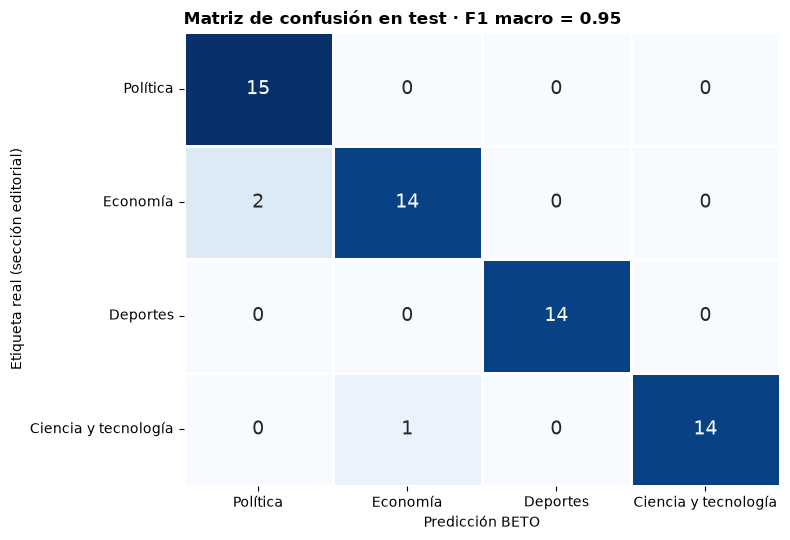

In [12]:
cm = confusion_matrix(test.etiqueta, test.pred_beto, labels=ETQ)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=[nu.NOMBRES[e] for e in ETQ], yticklabels=[nu.NOMBRES[e] for e in ETQ], ax=ax,
            annot_kws={"size": 14})
ax.set_xlabel("Predicción BETO"); ax.set_ylabel("Etiqueta real (sección editorial)")
ax.tick_params(axis="y", rotation=0)
ax.set_title(f"Matriz de confusión en test · F1 macro = {f1_beto:.2f}", loc="left", fontweight="bold")
plt.tight_layout()
fig.savefig(DIR_MODELO / "matriz_confusion.png", dpi=120)
plt.show()

In [13]:
errores = test[test.etiqueta != test.pred_beto][["titular", "medio", "etiqueta", "pred_beto", "conf_beto"]]
print(f"Errores en test: {len(errores)} de {len(test)}")
errores.sort_values("conf_beto", ascending=False)

Errores en test: 3 de 60


,titular,medio,etiqueta,pred_beto,conf_beto
56,Reforma tributaria: Ejecutivo pedirá facultades para modificar los regímenes de las pequeñas emp...,La República,economia,politica,0.841494
17,“Inventores del Futuro” 2026: así puedes participar en concurso nacional de escolares,El Comercio,ciencia_tecnologia,economia,0.756286
36,Gobierno de Keiko Fujimori anuncia subsidio de hasta 20% para transportistas ante alza de combus...,La República,economia,politica,0.690458


### Reflexión lingüística y temática sobre aciertos y errores

- **Deportes (F1 = 1.00):** es la categoría con el léxico más cerrado y formulaico: nombres de clubes (*Alianza Lima, Universitario, Melgar*), marcadores (*1-0*), fórmulas fijas (*"resumen y goles"*, *"| VIDEO"*, *"fecha, hora y canal"*). El modelo no necesita entender la noticia, le basta con reconocer el género textual.
- **Ciencia y tecnología (F1 = 0.97):** también tiene marcadores claros (*científicos, NASA, IA, app, hallazgo*). Su único error, *"Inventores del Futuro 2026: así puedes participar en concurso nacional de escolares"*, usa la fórmula de servicio *"así puedes…"*, típica de las notas de consumo de economía, y no contiene léxico científico.
- **Economía ↔ política (los otros 2 errores):** *"Reforma tributaria: Ejecutivo pedirá facultades para modificar los regímenes…"* y *"Gobierno de Keiko Fujimori anuncia subsidio… ante alza de combustibles"*. El **sujeto gramatical** es un actor político (*Ejecutivo, Gobierno*) y el **objeto** es económico (*régimen tributario, subsidio*). BETO se guía por el actor; la redacción, por el tema. Es la frontera natural más difusa del esquema de 4 categorías: la política económica pertenece a ambas.
- **Cautela estadística:** con 60 titulares de test, cada error vale 1.7 puntos de accuracy. En validación el F1 macro fue 0.867, así que el rendimiento real esperable está probablemente entre 0.87 y 0.95. Para afirmar una cifra exacta se necesitaría un test más grande o validación cruzada.

## 6. Módulos de innovación

### Innovación 1 · Análisis de sesgo editorial (Opción C)

¿Escriben ambos medios sus titulares de forma igual de "clasificable"? Se compara (a) la confianza del LLM y su acuerdo con la sección editorial por medio, (b) el desempeño de BETO por medio en test y (c) el vocabulario distintivo de cada medio mediante **log-odds con prior de Dirichlet** (Monroe et al., 2008), que corrige el ruido de las palabras poco frecuentes.

In [14]:
sesgo = df.groupby("medio").apply(lambda g: pd.Series({
    "confianza_LLM_media": g.confianza_llm.mean(),
    "pct_confianza_<0.6": (g.confianza_llm < 0.6).mean(),
    "acuerdo_LLM_editorial": (g.etiqueta == g.etiqueta_llm).mean(),
    "long_media_titular": g.titular.str.len().mean(),
    "pct_con_dos_puntos": g.titular.str.contains(":").mean(),
    "pct_con_cita": g.titular.str.contains(r"[“\"]").mean(),
})).T
sesgo.loc["acc_BETO_test"] = test.assign(ok=test.etiqueta == test.pred_beto).groupby("medio").ok.mean()
sesgo.round(3)

medio,El Comercio,La República
confianza_LLM_media,0.959,0.950
pct_confianza_<0.6,0.020,0.035
acuerdo_LLM_editorial,0.835,0.850
long_media_titular,97.415,101.520
pct_con_dos_puntos,0.525,0.655
pct_con_cita,0.195,0.215
acc_BETO_test,0.967,0.933


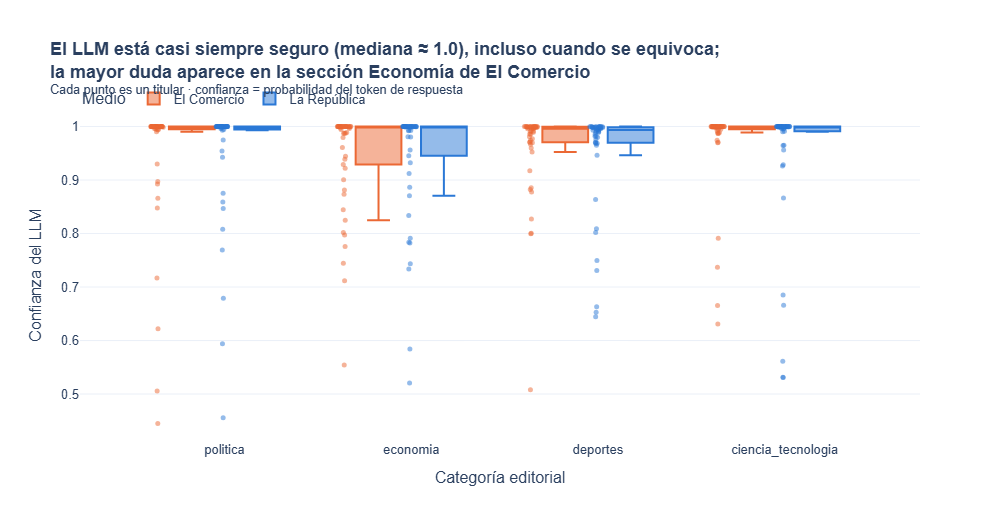

Acuerdo LLM–editorial por categoría y medio:
| etiqueta           |   El Comercio |   La República |
|:-------------------|--------------:|---------------:|
| ciencia_tecnologia |          0.94 |           0.84 |
| deportes           |          0.92 |           0.94 |
| economia           |          0.6  |           0.78 |
| politica           |          0.88 |           0.84 |


In [15]:
fig = px.box(df, x="etiqueta", y="confianza_llm", color="medio", points="all",
             color_discrete_map=COLOR_MEDIO, category_orders={"etiqueta": ETQ},
             labels={"confianza_llm": "Confianza del LLM", "etiqueta": "Categoría editorial", "medio": "Medio"},
             title="<b>El LLM está casi siempre seguro (mediana ≈ 1.0), incluso cuando se equivoca;<br>la mayor duda aparece en la sección Economía de El Comercio</b><br><sup>Cada punto es un titular · confianza = probabilidad del token de respuesta</sup>")
fig.update_traces(marker=dict(size=5, opacity=0.5))
fig.update_layout(**PLANTILLA, legend=dict(orientation="h", y=1.08))
fig.show()
acuerdo_cat = df.assign(ok=df.etiqueta == df.etiqueta_llm).pivot_table(index="etiqueta", columns="medio", values="ok").round(3)
print("Acuerdo LLM–editorial por categoría y medio:")
print(acuerdo_cat.to_markdown())

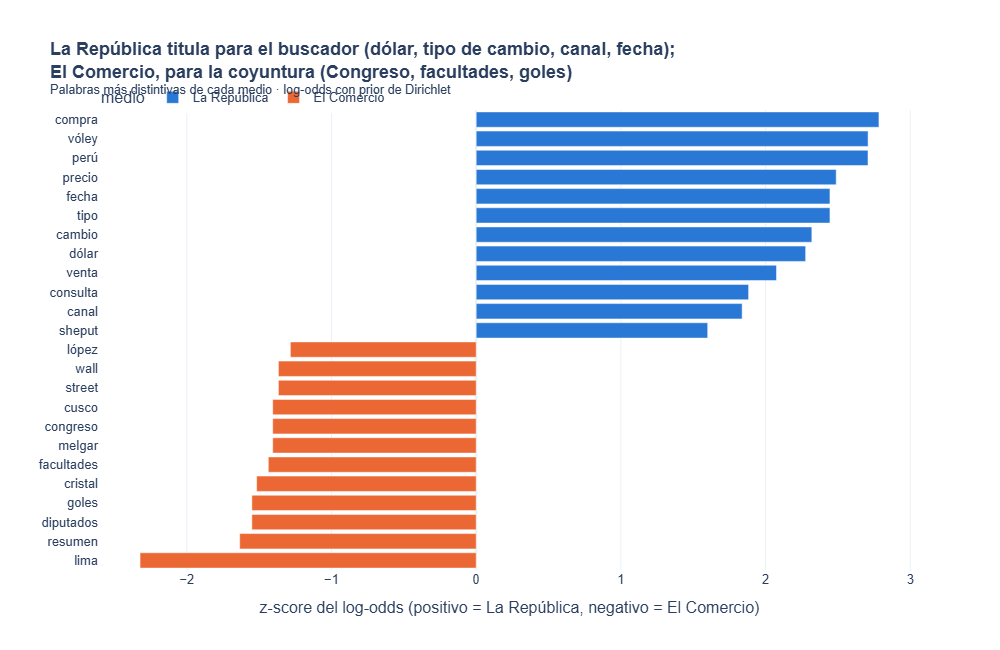

In [16]:
lr_txt = df[df.medio == "La República"].titular.tolist()
ec_txt = df[df.medio == "El Comercio"].titular.tolist()
top_lr, top_ec = nu.log_odds_distintivas(lr_txt, ec_txt, top=12)
voc = pd.concat([top_lr.assign(medio="La República"),
                 top_ec.assign(medio="El Comercio")])
fig = px.bar(voc, x="z", y="palabra", color="medio", orientation="h", color_discrete_map=COLOR_MEDIO,
             labels={"z": "z-score del log-odds (positivo = La República, negativo = El Comercio)", "palabra": ""},
             title="<b>La República titula para el buscador (dólar, tipo de cambio, canal, fecha);<br>El Comercio, para la coyuntura (Congreso, facultades, goles)</b><br><sup>Palabras más distintivas de cada medio · log-odds con prior de Dirichlet</sup>")
fig.update_layout(**{**PLANTILLA, "height": 650}, yaxis=dict(categoryorder="total ascending"),
                  legend=dict(orientation="h", y=1.06))
fig.show()

**Lectura del sesgo editorial (Opción C):**

1. **La misma etiqueta no significa lo mismo en ambos medios.** El acuerdo global del LLM con la sección editorial es casi idéntico (El Comercio 83.5%, La República 85.0%), pero en **Economía cae a 60% en El Comercio frente a 78% en La República**. La sección económica de El Comercio funciona como "cajón de sastre": incluye notas sobre presupuesto del Minsa, El Niño, conciertos de BTS, feriados y columnas de opinión (*"La IA agnóstica"*). La de La República está dominada por notas de servicio sobre el precio del dólar, léxicamente obvias.
2. **Estilos de titulación distintos.** Las palabras más distintivas de La República son de **servicio/SEO** (*compra, venta, tipo de cambio, dólar, consulta, canal, fecha*). Las de El Comercio son de **coyuntura parlamentaria** (*Congreso, diputados, facultades*), mercados (*Wall Street*) y **resúmenes deportivos** (*goles, resumen, Melgar, Cristal*). La República también usa más los dos puntos (66% vs. 53%).
3. **Consecuencia para el modelo:** BETO acierta 96.7% en El Comercio y 93.3% en La República, una diferencia de un solo titular, sin relevancia estadística. Pero que cada medio tenga fórmulas propias implica que un clasificador entrenado con un solo medio aprendería su estilo y no el tema. El diseño 50/50 de la Opción C es justamente lo que reduce ese riesgo.

### Innovación 2 · NER peruano por categoría

`mrm8488/bert-spanish-cased-finetuned-ner` (BETO afinado en CoNLL-2002 español) extrae personas (PER), organizaciones (ORG) y lugares (LOC) de cada titular. Se filtran entidades con score ≥ 0.6. El resultado se guarda en `datos/entidades_ner.csv` para la app.

In [17]:
ner = nu.cargar_ner()
filas = []
for i, r in df.iterrows():
    for e in nu.extraer_entidades(ner, r.titular):
        filas.append({"idx": i, "medio": r.medio, "etiqueta": r.etiqueta, **e})
ents = pd.DataFrame(filas)
ents.to_csv(RAIZ / "datos" / "entidades_ner.csv", index=False, encoding="utf-8")
print(f"{len(ents)} entidades en {ents.idx.nunique()} titulares "
      f"({ents.idx.nunique() / len(df):.0%} de titulares con al menos una entidad)")
pd.crosstab(ents.etiqueta, ents.tipo, margins=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: mrm8488/bert-spanish-cased-finetuned-ner
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


576 entidades en 307 titulares (77% de titulares con al menos una entidad)


tipo,LOC,ORG,PER,All
etiqueta,,,,
ciencia_tecnologia,22,21,14,57
deportes,22,122,68,212
economia,57,40,11,108
politica,16,85,98,199
All,117,268,191,576


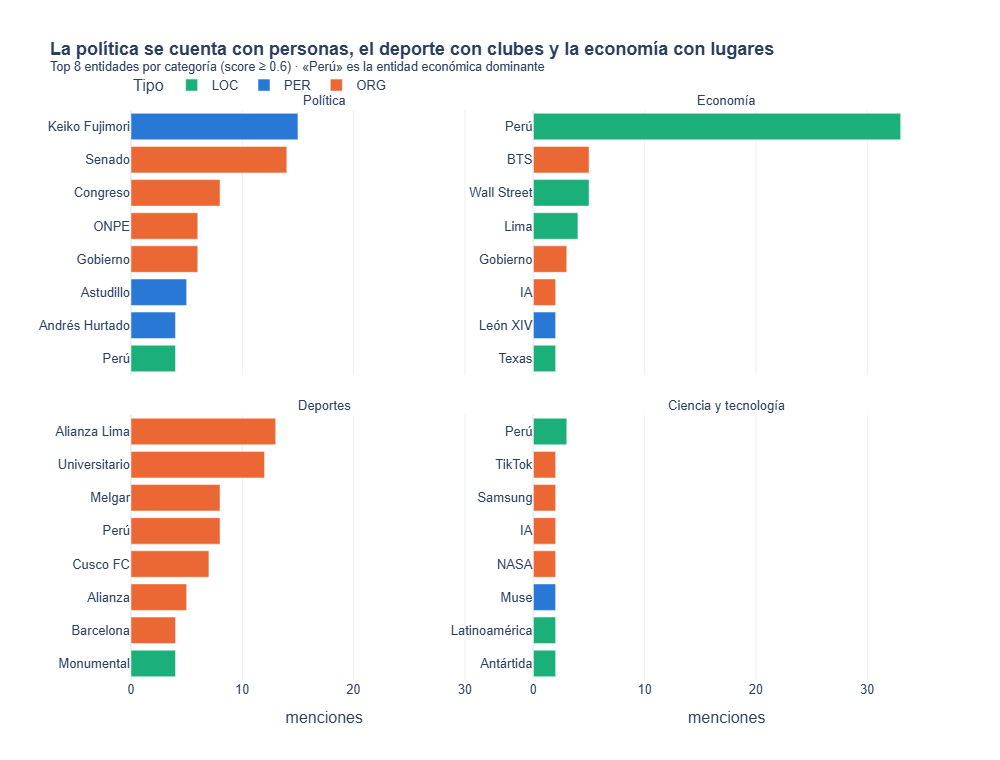

In [18]:
top_ents = (ents.groupby(["etiqueta", "tipo", "entidad"]).size().rename("n").reset_index()
                .sort_values("n", ascending=False).groupby("etiqueta").head(8))
fig = px.bar(top_ents, x="n", y="entidad", color="tipo", facet_col="etiqueta", facet_col_wrap=2,
             orientation="h", category_orders={"etiqueta": ETQ},
             color_discrete_map={"PER": "#2a78d6", "ORG": "#eb6834", "LOC": "#1baf7a"},
             labels={"n": "menciones", "entidad": "", "tipo": "Tipo"},
             title="<b>La política se cuenta con personas, el deporte con clubes y la economía con lugares</b><br><sup>Top 8 entidades por categoría (score ≥ 0.6) · «Perú» es la entidad económica dominante</sup>")
fig.update_yaxes(matches=None, showticklabels=True, categoryorder="total ascending")
fig.for_each_annotation(lambda a: a.update(text=nu.NOMBRES.get(a.text.split("=")[-1], a.text)))
fig.update_layout(**{**PLANTILLA, "height": 760}, legend=dict(orientation="h", y=1.07))
fig.show()

**Lectura del NER:** se extrajeron 576 entidades y el 77% de los titulares tiene al menos una. Cada categoría tiene una "firma" distinta:
- **Política** se narra con **personas** (98 de 199 entidades son PER: *Keiko Fujimori*, *Astudillo*) e instituciones (*Senado, Congreso, ONPE*).
- **Deportes** se narra con **organizaciones** (122 ORG: *Alianza Lima, Universitario, Melgar, Cusco FC*). Aquí *Perú* aparece como ORG porque el modelo lo interpreta como la selección, una metonimia correcta.
- **Economía** es la única dominada por **lugares** (57 LOC; *Perú* aparece 33 veces, *Wall Street*, *Lima*): la economía se titula a escala país o mercado.
- **Ciencia y tecnología** casi no tiene entidades (57 en 100 titulares). Sus titulares son genéricos (*"científicos descubren…"*, *"un estudio revela…"*), así que los rasgos basados en entidades ayudarían poco en esa clase.

Limitaciones observadas: el modelo (entrenado con noticias españolas de CoNLL-2002) etiqueta mal algunos nombres artísticos (*Muse* como PER). Con la agregación por defecto (`simple`) partía nombres en subpalabras (*Cu* + *sco FC*); se usó `aggregation_strategy="max"`, que lo corrige.

### Innovación 3 · Buscador semántico (embeddings + similitud coseno)

`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` (multilingüe, 384 dimensiones; se prefiere a `all-MiniLM-L6-v2` porque este último se entrenó solo en inglés). Los vectores se normalizan, así que el producto punto es la similitud coseno. Los embeddings se guardan en `datos/embeddings.npy` (≈0.6 MB) para que la app no tenga que recalcularlos.

Como subproducto, los mismos embeddings + una regresión logística dan un **cuarto clasificador** muy barato para la tabla comparativa.

In [19]:
buscador = nu.BuscadorSemantico(df.titular.tolist())
np.save(RAIZ / "datos" / "embeddings.npy", buscador.emb)
print("Embeddings:", buscador.emb.shape)

for consulta in ["vacancia presidencial y crisis en el Congreso", "sube el precio del dólar",
                 "clásico Universitario Alianza Lima", "inteligencia artificial en celulares"]:
    print(f"\n🔎 {consulta}")
    for i, s in buscador.buscar(consulta, k=3):
        print(f"   {s:.3f} [{df.etiqueta[i]:<18}] {df.titular[i][:95]}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings: (400, 384)

🔎 vacancia presidencial y crisis en el Congreso
   0.633 [politica          ] Congreso: Este lunes 12 se inicia la semana de representación para senadores y diputados
   0.565 [politica          ] Paciencia, ¡la nuestra!, una crónica de Fernando Vivas sobre el pedido de facultades y el papel
   0.525 [politica          ] Tensión en Comisión de Constitución del Senado: sesión fue suspendida varios minutos por alterc

🔎 sube el precio del dólar
   0.705 [economia          ] Precio del dólar hoy: a cuánto está el cierre del tipo de cambio del viernes 9 de octubre
   0.652 [economia          ] Precio del dólar hoy en Perú, sábado 19 de septiembre: consulta el tipo de cambio para compra y
   0.650 [economia          ] Precio del dólar hoy en Perú, domingo 27 de septiembre: consulta el tipo de cambio para compra 

🔎 clásico Universitario Alianza Lima
   0.730 [deportes          ] Alianza Lima: Conoce el fixture de las 6 fechas finales del cuadro íntimo en el Torneo Cl

In [20]:
from sklearn.linear_model import LogisticRegression

emb = buscador.emb
m_tr = (df.particion == "train").values
m_te = (df.particion == "test").values
logreg = LogisticRegression(max_iter=2000, C=4.0).fit(emb[m_tr], df.etiqueta[m_tr])
pred_emb = logreg.predict(emb[m_te])
acc_emb = accuracy_score(df.etiqueta[m_te], pred_emb)
f1_emb = f1_score(df.etiqueta[m_te], pred_emb, average="macro")
print(f"Embeddings + LogReg (test) Accuracy = {acc_emb:.3f} | F1 macro = {f1_emb:.3f}")

Embeddings + LogReg (test) Accuracy = 0.950 | F1 macro = 0.949


## 7. Tabla comparativa final

Para comparar en igualdad de condiciones, todos los métodos se evalúan también en **los mismos 40 titulares de test** usados por el zero-shot. La latencia se mide por titular en esta máquina (RTX 3060 / i5-11400F); la columna *Hardware* indica dónde se midió cada una. BETO se mide a propósito en CPU, que es como corre en la app.

In [21]:
clf = nu.ClasificadorTitulares(DIR_MODELO)
t0 = time.perf_counter()
for t in test.titular[:30]:
    clf.predecir(t)
lat_beto_cpu = 1000 * (time.perf_counter() - t0) / 30

t0 = time.perf_counter()
for t in test.titular[:30]:
    logreg.predict(buscador.codificar([t]))
lat_emb = 1000 * (time.perf_counter() - t0) / 30

m40 = muestra40.merge(test[["url", "pred_beto"]], on="url").merge(df[["url", "etiqueta_llm"]], on="url")
m40["pred_emb"] = logreg.predict(emb[df.set_index("url").index.get_indexer(m40.url)])
f1_40 = lambda col: f1_score(m40.etiqueta, m40[col], average="macro")

tabla = pd.DataFrame([
    {"Método": "Zero-shot XNLI (BETO-XNLI)", "F1 macro (40 comunes)": f1_40("pred_zero_shot"),
     "Accuracy test": np.nan, "F1 macro test": np.nan, "Latencia ms/titular": lat_zs,
     "Hardware": "GPU", "Costo": "Gratis, sin datos etiquetados", "Entrenamiento": "Ninguno"},
    {"Método": "LLM débil (Qwen2.5-3B local)", "F1 macro (40 comunes)": f1_40("etiqueta_llm"),
     "Accuracy test": acc_llm_test, "F1 macro test": f1_llm_test, "Latencia ms/titular": lat_llm,
     "Hardware": "GPU", "Costo": "GPU ≥ 8 GB o API de pago", "Entrenamiento": "Ninguno (prompt)"},
    {"Método": "Embeddings + LogReg", "F1 macro (40 comunes)": f1_40("pred_emb"),
     "Accuracy test": acc_emb, "F1 macro test": f1_emb, "Latencia ms/titular": lat_emb,
     "Hardware": "GPU (encoder)", "Costo": "470 MB, corre en CPU", "Entrenamiento": "Segundos"},
    {"Método": "BETO fine-tuned", "F1 macro (40 comunes)": f1_40("pred_beto"),
     "Accuracy test": acc_beto, "F1 macro test": f1_beto, "Latencia ms/titular": lat_beto_cpu,
     "Hardware": "CPU", "Costo": "440 MB, corre en CPU", "Entrenamiento": "~1 min GPU (280 titulares)"},
])
print(tabla.round(3).to_markdown(index=False, floatfmt=".3f"))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

| Método                       |   F1 macro (40 comunes) |   Accuracy test |   F1 macro test |   Latencia ms/titular | Hardware      | Costo                         | Entrenamiento              |
|:-----------------------------|------------------------:|----------------:|----------------:|----------------------:|:--------------|:------------------------------|:---------------------------|
| Zero-shot XNLI (BETO-XNLI)   |                   0.665 |         nan     |         nan     |                31.125 | GPU           | Gratis, sin datos etiquetados | Ninguno                    |
| LLM débil (Qwen2.5-3B local) |                   0.821 |           0.817 |           0.817 |               117.918 | GPU           | GPU ≥ 8 GB o API de pago      | Ninguno (prompt)           |
| Embeddings + LogReg          |                   0.950 |           0.950 |           0.949 |                 9.606 | GPU (encoder) | 470 MB, corre en CPU          | Segundos                   |
| BETO fine-tuned   

In [22]:
metricas = {
    "fecha_evaluacion": FECHA_ETIQUETADO,
    "n_noticias": len(df), "n_train": len(train), "n_val": len(val), "n_test": len(test),
    "beto": {"accuracy_test": acc_beto, "f1_macro_test": f1_beto, "latencia_ms": lat_beto_cpu},
    "zero_shot": {"accuracy_40": acc_zs, "f1_macro_40": f1_zs, "latencia_ms": lat_zs},
    "llm": {"modelo": llm_df.modelo_llm.iloc[0], "accuracy_400": acc_llm, "f1_macro_400": f1_llm,
            "f1_macro_test": f1_llm_test, "acuerdo_auditoria_20": acuerdo_audit, "latencia_ms": lat_llm},
    "embeddings_logreg": {"accuracy_test": acc_emb, "f1_macro_test": f1_emb, "latencia_ms": lat_emb},
    "tabla_comparativa": tabla.round(4).astype(object).where(tabla.notna(), None).to_dict(orient="records"),
}
(DIR_MODELO / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps({k: metricas[k] for k in ["beto", "zero_shot", "llm"]}, ensure_ascii=False, indent=1))

{
 "beto": {
  "accuracy_test": 0.95,
  "f1_macro_test": 0.9515607619577309,
  "latencia_ms": 34.96561999976014
 },
 "zero_shot": {
  "accuracy_40": 0.675,
  "f1_macro_40": 0.6646739130434782,
  "latencia_ms": 31.124912499217317
 },
 "llm": {
  "modelo": "qwen_local:Qwen/Qwen2.5-3B-Instruct",
  "accuracy_400": 0.8425,
  "f1_macro_400": 0.842884042346106,
  "f1_macro_test": 0.817128158271095,
  "acuerdo_auditoria_20": 0.8,
  "latencia_ms": 117.91847999993479
 }
}


### ¿Qué modelo llevar a producción?

| Criterio | Zero-shot | LLM débil (Qwen2.5-3B) | Embeddings + LogReg | **BETO fine-tuned** |
|---|---|---|---|---|
| Precisión (F1 macro) | 0.665 (40) | 0.817 (test) | 0.949 (test) | **0.952 (test) · 0.975 (40)** |
| Latencia | ~31 ms (GPU) | ~118 ms (GPU) | ~9 ms | ~35 ms **en CPU** |
| Costo | nulo | GPU ≥ 8 GB o API de pago por llamada | nulo | nulo (440 MB) |
| Necesita datos etiquetados | no | no | sí (280) | sí (280) |

**Elección: BETO fine-tuned** para la app. Tiene la mejor precisión, corre en CPU en ~35 ms sin costo por consulta y no depende de servicios externos. Dos matices honestos:
- **Embeddings + LogReg empata en la práctica** (57/60 aciertos en ambos; la diferencia de F1 está dentro del ruido de un test de 60). Es 4 veces más rápido de entrenar y más liviano, así que sería la alternativa si el despliegue tuviera poca memoria o si hubiera que reentrenar con frecuencia.
- **El LLM no compite como clasificador final**, pero sí sirve como **herramienta de etiquetado**: sin ningún ejemplo de entrenamiento coincide en 84% con la redacción. El flujo recomendado es: el LLM pre-etiqueta noticias de secciones nuevas, un humano audita una muestra (fijándose en siglas institucionales, donde falla con confianza alta) y luego se reentrena BETO.

**Respuesta a la pregunta guía:** sí. Con solo 280 titulares de entrenamiento, un transformer en español clasifica titulares peruanos en 4 secciones con F1 macro ≈ 0.95. El límite no es el modelo sino la definición de las categorías: la frontera entre política y economía (la política económica) y las secciones "cajón de sastre" de cada medio.